# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab:** no se usa. La notebook se entrega ejecutada en el repositorio
(opción 1 de la sección 8.2 del enunciado); se corrió en local con GPU (GTX 1650, 4 GB).

## Equipo
- Alumno 1 : Facundo Quinteros — Q-0493/6 — @FacuQuinteros03
- Alumno 2 : Roberto Lasarte — L-3370/7 — @RoberLasarte332

## 1. Clonar el repositorio

Solo si se trabaja en Colab (en local la notebook se corre desde la raíz del repositorio).

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/FacuQuinteros03/tuia-dog-recognition-app.git"
    !git clone -b feature/tp2-razas-perros $REPO_URL proyecto
    %cd proyecto
print("Colab:", IN_COLAB)

Colab: False


## 2. Instalar dependencias

En local se usa el entorno de `requirements.txt` (más `imagehash`, para el hash perceptual).
En Colab solo se instala lo que falta.

In [2]:
if IN_COLAB:
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime ultralytics imagehash

## 3. Configuración del entorno

Se fijan las semillas (`random`, `numpy`, `torch`) y los paths. Los pesos preentrenados de
torchvision se cachean en `models/torch` (`TORCH_HOME`, igual que en la app) y YOLO en
`models/yolov8n.pt`. Los resultados intermedios costosos (embeddings, detecciones de YOLO,
hashes) se guardan en `output/nb1/`, que está fuera del control de versiones.

In [3]:
import os
import json
import random
import warnings
from pathlib import Path

ROOT = Path.cwd()
os.environ["USE_PGVECTOR"] = "false"
os.environ.setdefault("TORCH_HOME", str(ROOT / "models" / "torch"))
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from lib.config import settings
from lib.preprocessing import (IMAGENET_MEAN, IMAGENET_STD, PAD_RGB, bgr_to_rgb,
                               build_train_augmentation, letterbox, preprocess_rgb, read_bgr)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RAW = ROOT / "data" / "dataset"            # dataset tal como lo descarga scripts/download_dataset.py
CLEAN = RAW / "clean"                      # dataset filtrado y re-particionado (lo produce esta notebook)
INDEP = RAW / "independent"                # conjunto independiente: una carpeta por raza
SCENES = RAW / "independent_scenes"        # escenas para la Etapa 3: multi_dog / no_dog
CACHE = ROOT / "output" / "nb1"
CACHE.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMAGE_SIZE = settings.image_size

pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90
# Figuras en JPEG: las grillas de fotos en PNG hacen que la notebook pese demasiado para GitHub.
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})
print("ROOT:", ROOT)
print("IMAGE_SIZE:", IMAGE_SIZE, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

/root/venvs/tp2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: /mnt/c/Users/facuq/Desktop/5to Cuatrimestre/tuia-dog-recognition-app
IMAGE_SIZE: 224 | device: cuda NVIDIA GeForce GTX 1650


## 4. Descargar el dataset

In [4]:
if not (RAW / "train").is_dir():
    !python scripts/download_dataset.py
print(sorted(p.name for p in RAW.iterdir()))

['.gitkeep', 'clean', 'dogs.csv', 'independent', 'independent_candidates', 'independent_candidates.csv', 'independent_scenes', 'test', 'train', 'valid']


## 5. Descripción del dataset

Primero se arma un inventario con una fila por archivo (split, carpeta, raza, ruta) y las
propiedades de cada imagen. El nombre de la raza se **normaliza** (espacios repetidos) porque,
como se ve abajo, el dataset no usa el mismo nombre de carpeta en todos los splits.

In [5]:
from PIL import Image


def normalize_breed(name: str) -> str:
    return " ".join(name.split())


rows = []
for split in ("train", "valid", "test"):
    for folder in sorted(p for p in (RAW / split).iterdir() if p.is_dir()):
        for f in sorted(folder.iterdir()):
            row = {"split": split, "folder": folder.name, "breed": normalize_breed(folder.name),
                   "path": f.relative_to(RAW).as_posix(), "ext": f.suffix.lower(),
                   "bytes": f.stat().st_size}
            try:
                with Image.open(f) as im:
                    row.update(width=im.width, height=im.height, mode=im.mode, fmt=im.format)
                    im.verify()
                row["readable"] = True
            except Exception:
                row["readable"] = False
            rows.append(row)
inv = pd.DataFrame(rows)

print("Archivos:", len(inv))
print("Carpetas distintas:", inv["folder"].nunique(), "| razas (nombre normalizado):", inv["breed"].nunique())
print("\nCarpetas cuyo nombre no coincide entre splits:")
display(inv[inv["folder"] != inv["breed"]].groupby(["split", "folder"]).size().rename("imagenes").to_frame())

Archivos: 9346
Carpetas distintas: 71 | razas (nombre normalizado): 70

Carpetas cuyo nombre no coincide entre splits:


,,imagenes
split,folder,
valid,American Spaniel,10


In [6]:
counts = inv.pivot_table(index="breed", columns="split", values="path", aggfunc="count").fillna(0).astype(int)
counts = counts[["train", "valid", "test"]]
summary = pd.DataFrame({
    "razas": [inv["breed"].nunique()],
    "imagenes": [len(inv)],
    "train": [counts["train"].sum()], "valid": [counts["valid"].sum()], "test": [counts["test"].sum()],
    "formatos": [", ".join(sorted(inv["fmt"].dropna().unique()))],
    "modos de color": [", ".join(sorted(inv["mode"].dropna().unique()))],
    "resoluciones (WxH)": [", ".join(sorted({f"{w}x{h}" for w, h in zip(inv.width, inv.height)}))],
    "ilegibles": [(~inv["readable"]).sum()],
})
display(summary.T.rename(columns={0: "valor"}))
print("Razas:", ", ".join(counts.index))

,valor
razas,70
imagenes,9346
train,7946
valid,700
test,700
formatos,JPEG
modos de color,RGB
resoluciones (WxH),224x224
ilegibles,0


Razas: Afghan, African Wild Dog, Airedale, American Hairless, American Spaniel, Basenji, Basset, Beagle, Bearded Collie, Bermaise, Bichon Frise, Blenheim, Bloodhound, Bluetick, Border Collie, Borzoi, Boston Terrier, Boxer, Bull Mastiff, Bull Terrier, Bulldog, Cairn, Chihuahua, Chinese Crested, Chow, Clumber, Cockapoo, Cocker, Collie, Corgi, Coyote, Dalmation, Dhole, Dingo, Doberman, Elk Hound, French Bulldog, German Sheperd, Golden Retriever, Great Dane, Great Perenees, Greyhound, Groenendael, Irish Spaniel, Irish Wolfhound, Japanese Spaniel, Komondor, Labradoodle, Labrador, Lhasa, Malinois, Maltese, Mex Hairless, Newfoundland, Pekinese, Pit Bull, Pomeranian, Poodle, Pug, Rhodesian, Rottweiler, Saint Bernard, Schnauzer, Scotch Terrier, Shar_Pei, Shiba Inu, Shih-Tzu, Siberian Husky, Vizsla, Yorkie


**Fuente y licencia.** Dataset publicado en Kaggle por Gerry (`gpiosenka`), versión 2
(1/7/2021), con licencia **CC0: Public Domain**: permite usarlo, modificarlo y redistribuirlo
sin restricciones, así que el uso académico que le damos está permitido. Según su descripción,
las imágenes se obtuvieron con búsquedas en internet por raza, se revisaron a mano, se eliminaron
duplicados entre train, valid y test con un programa propio del autor y se redimensionaron a
224×224×3 en JPG. Esa afirmación sobre los duplicados se verifica en la sección 7.

Observaciones sobre las etiquetas:

- La raza American Spaniel aparece como `American  Spaniel` (con doble espacio) **solo en
  `valid`**. Si cada split se cargara por separado con `ImageFolder`, `valid` tendría una clase
  distinta y los índices de clase quedarían corridos respecto de `train` (es el error de "perder
  el mapeo índice → raza"). Se resuelve normalizando el nombre y guardando una única lista de
  clases (`data/classes.json`).
- Hay nombres mal escritos (`Dalmation`, `German Sheperd`, `Great Perenees`, `Bermaise`). Se
  **mantienen tal cual** porque son las etiquetas del dataset y el enunciado pide usar las mismas
  razas que las carpetas: cambiarlos solo complicaría comparar con otros trabajos.
- Cuatro clases no son razas de perro doméstico sino cánidos salvajes: `African Wild Dog`,
  `Coyote`, `Dhole` y `Dingo`.

### 5.1 Encuadre de las imágenes vs. recortes de YOLO

Para medir cómo están encuadradas se corre el detector de la Etapa 3 (YOLOv8n preentrenado en
COCO, el mismo que usa la app) sobre todas las imágenes y se registra cuántos perros detecta,
qué fracción de la imagen ocupa la caja del perro más grande y si aparecen personas u otros
animales. En la misma pasada se calculan las métricas que se usan en las secciones 6 y 7
(brillo, contraste, nitidez, hash perceptual y embeddings), para leer cada imagen una sola vez.

In [7]:
import imagehash
import torchvision
from ultralytics import YOLO

COCO_DOG, COCO_CAT, COCO_PERSON = settings.yolo_dog_class_id, 15, 0
# Clases de ImageNet: 151-268 razas de perro, 269-275 lobos, coyote, dingo, dhole, perro salvaje africano.
IMAGENET_CANIDS = list(range(151, 276))


def load_backbone():
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
    model = torchvision.models.resnet18(weights=weights).eval().to(DEVICE)
    feats = {}
    model.avgpool.register_forward_hook(lambda m, i, o: feats.__setitem__("emb", o.flatten(1)))
    return model, feats


def analyze_images(paths: list[Path], batch: int = 64) -> tuple[pd.DataFrame, np.ndarray]:
    """Una pasada por imagen: estadisticas, nitidez, pHash, YOLO y embedding ResNet18 (ImageNet)."""
    yolo = YOLO(settings.yolo_model if Path(settings.yolo_model).exists() else "models/yolov8n.pt")
    backbone, feats = load_backbone()
    recs, embs = [], []
    for i in range(0, len(paths), batch):
        imgs = [read_bgr(p) for p in paths[i:i + batch]]
        for p, bgr in zip(paths[i:i + batch], imgs):
            gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            recs.append({
                "brightness": float(gray.mean()), "contrast": float(gray.std()),
                "lap_var": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
                "phash": str(imagehash.phash(Image.fromarray(bgr_to_rgb(bgr)))),
                "aspect": bgr.shape[1] / bgr.shape[0],
            })
        results = yolo(imgs, conf=0.25, verbose=False)
        for rec, res, bgr in zip(recs[-len(imgs):], results, imgs):
            cls = res.boxes.cls.cpu().numpy().astype(int)
            xyxy = res.boxes.xyxy.cpu().numpy()
            area = (xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1]) / (bgr.shape[0] * bgr.shape[1])
            dogs = cls == COCO_DOG
            rec.update(n_dogs=int(dogs.sum()), n_persons=int((cls == COCO_PERSON).sum()),
                       n_cats=int((cls == COCO_CAT).sum()),
                       dog_area=float(area[dogs].max()) if dogs.any() else 0.0,
                       dog_conf=float(res.boxes.conf.cpu().numpy()[dogs].max()) if dogs.any() else 0.0)
        x = torch.from_numpy(np.stack([preprocess_rgb(bgr_to_rgb(b), IMAGE_SIZE) for b in imgs])).to(DEVICE)
        with torch.no_grad():
            probs = backbone(x).softmax(1)
        for rec, pr in zip(recs[-len(imgs):], probs.cpu().numpy()):
            rec["canid_prob"] = float(pr[IMAGENET_CANIDS].sum())
        e = torch.nn.functional.normalize(feats["emb"], dim=1)
        embs.append(e.cpu().numpy().astype(np.float32))
    return pd.DataFrame(recs), np.concatenate(embs)


feat_csv, emb_npy = CACHE / "features.csv", CACHE / "embeddings.npy"
if feat_csv.exists() and emb_npy.exists():
    feats_df, EMB = pd.read_csv(feat_csv, dtype={"phash": str}), np.load(emb_npy)
else:
    feats_df, EMB = analyze_images([RAW / p for p in inv["path"]])
    feats_df.to_csv(feat_csv, index=False)
    np.save(emb_npy, EMB)
df = pd.concat([inv.reset_index(drop=True), feats_df], axis=1)
print(df.shape, EMB.shape)

(9346, 22) (9346, 512)


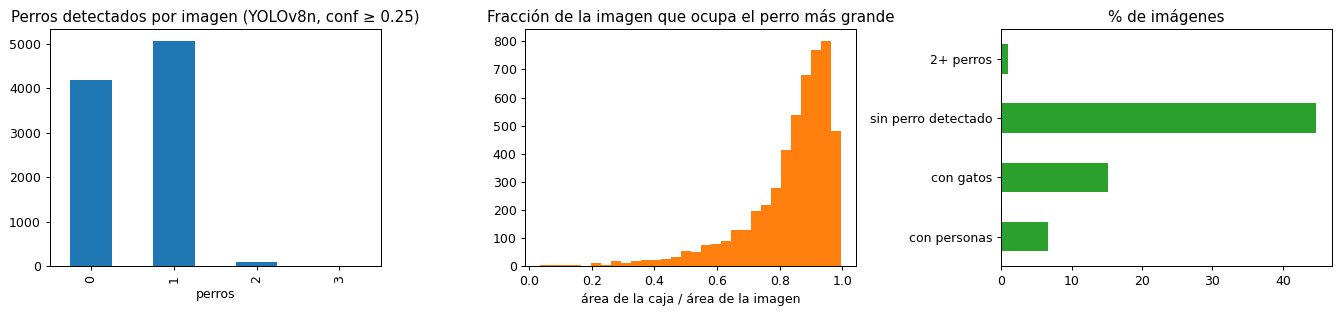

,count,mean,std,min,10%,25%,50%,75%,90%,max
dog_area,5165.0,0.833,0.145,0.036,0.638,0.784,0.876,0.932,0.963,0.996


Razas con mayor % de imágenes donde YOLO no detecta un perro:


,% sin perro detectado
breed,
Komondor,97.6
Coyote,91.3
Dhole,90.8
Irish Spaniel,82.7
Irish Wolfhound,80.4
Poodle,77.4
Newfoundland,75.5
Groenendael,74.1


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
df["n_dogs"].clip(upper=4).value_counts().sort_index().rename({4: "4+"}).plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Perros detectados por imagen (YOLOv8n, conf ≥ 0.25)")
axes[0].set_xlabel("perros")
axes[1].hist(df.loc[df.n_dogs > 0, "dog_area"], bins=30, color="tab:orange")
axes[1].set_title("Fracción de la imagen que ocupa el perro más grande")
axes[1].set_xlabel("área de la caja / área de la imagen")
other = pd.Series({"con personas": (df.n_persons > 0).mean(), "con gatos": (df.n_cats > 0).mean(),
                   "sin perro detectado": (df.n_dogs == 0).mean(), "2+ perros": (df.n_dogs >= 2).mean()}) * 100
other.plot.barh(ax=axes[2], color="tab:green")
axes[2].set_title("% de imágenes")
plt.tight_layout()
plt.show()

framing = df.loc[df.n_dogs > 0, "dog_area"].describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("dog_area").T
display(framing.round(3))
low = df.groupby("breed")["n_dogs"].apply(lambda s: (s == 0).mean() * 100).sort_values(ascending=False)
print("Razas con mayor % de imágenes donde YOLO no detecta un perro:")
display(low.head(8).round(1).to_frame("% sin perro detectado"))

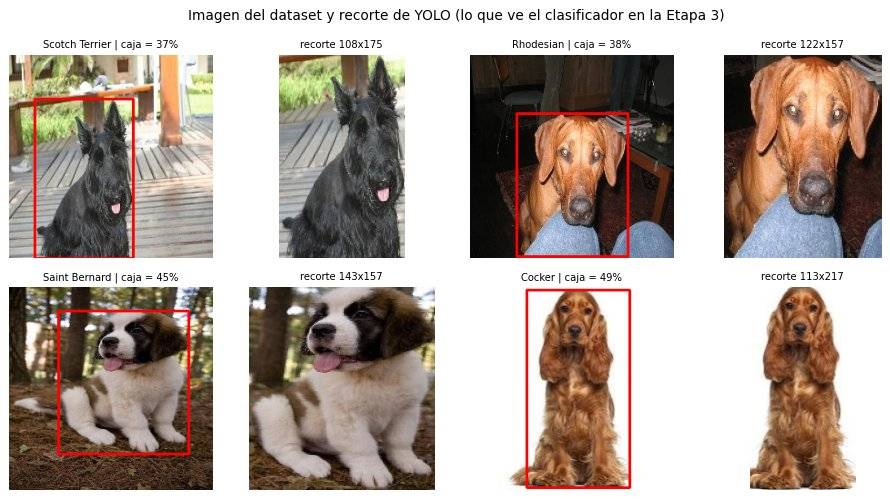

In [9]:
def show_grid(items, ncols=6, size=2.4, title=None):
    """items: lista de (imagen RGB, titulo)."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.08))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, (img, t) in zip(np.atleast_1d(axes).ravel(), items):
        ax.imshow(img)
        ax.set_title(t, fontsize=8)
    if title:
        fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()


def rgb(path):
    return bgr_to_rgb(read_bgr(RAW / path))


# Ejemplo: imagen del dataset, caja de YOLO y recorte que recibiria el clasificador en la Etapa 3.
yolo_demo = YOLO("models/yolov8n.pt")
examples = df[(df.n_dogs == 1) & (df.dog_area.between(0.25, 0.5))].sample(4, random_state=SEED)
items = []
for _, r in examples.iterrows():
    img = rgb(r.path)
    res = yolo_demo(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), conf=0.25, classes=[COCO_DOG], verbose=False)[0]
    x1, y1, x2, y2 = res.boxes.xyxy[0].cpu().numpy().astype(int)
    boxed = img.copy()
    cv2.rectangle(boxed, (x1, y1), (x2, y2), (255, 0, 0), 2)
    items += [(boxed, f"{r.breed} | caja = {r.dog_area:.0%}"), (img[y1:y2, x1:x2], f"recorte {x2-x1}x{y2-y1}")]
show_grid(items, ncols=4, size=2.6, title="Imagen del dataset y recorte de YOLO (lo que ve el clasificador en la Etapa 3)")

**Interpretación.**

- **Las imágenes ya son prácticamente recortes del perro.** Cuando YOLO detecta el perro, la caja
  ocupa una mediana de **88%** de la imagen (el 90% de las imágenes está por encima de 64%). El
  autor del dataset recortó y centró al perro antes de redimensionar a 224×224.
- **YOLO no detecta ningún perro en el 45% de las imágenes del dataset** y en el 15% detecta un
  "gato". No es que falte el perro: YOLOv8n se entrenó con escenas de COCO, donde los objetos
  aparecen completos y con contexto, y le cuesta reconocer un primer plano que llena todo el
  cuadro. Los fallos se concentran en razas de aspecto poco común (Komondor 98%, Poodle 77%,
  Irish Spaniel 83%) y en los cánidos salvajes (Coyote y Dhole, más del 90%).
- **Diferencia con lo que verá el clasificador en la Etapa 3:** allí el clasificador no recibe
  estas imágenes sino recortes de YOLO sobre fotos reales: encuadre todavía más ajustado (sin
  fondo), relación de aspecto cualquiera (no cuadrada) y resolución variable (un perro chico en una
  foto grande da un recorte de pocos píxeles que hay que ampliar). Es un cambio de dominio que se
  mide con el conjunto independiente (sección 8) y que se mitiga con el letterbox (sección 9) y con
  la augmentation de encuadre (sección 10).
- **Riesgo para la Etapa 3:** si el detector no encuentra el perro, el pipeline no clasifica nada.
  Las razas con pelaje o forma poco comunes son las más expuestas; el umbral `YOLO_CONF_THRESHOLD`
  se estudia en la Etapa 3 con las escenas del conjunto independiente, donde los perros aparecen
  con contexto (que es el caso para el que YOLO fue entrenado).

### 5.2 Limitaciones del dataset

- **Cuatro clases no son razas** (African Wild Dog, Coyote, Dhole, Dingo) y **no hay perros
  mestizos**: frente a un mestizo, el sistema igual va a elegir una de las 70 clases. Las únicas
  cruzas presentes (Cockapoo, Labradoodle) son cruzas "de diseño" con poodle.
- **Razas muy parecidas entre sí** (sección 6.3): Boston Terrier y Bulldog, American Hairless y
  Mex Hairless, Lhasa y Shih-Tzu, Cockapoo y Labradoodle, German Sheperd y Malinois. Son la
  principal fuente esperada de errores y van a dominar la matriz de confusión.
- **Sesgo de origen web:** muchas fotos de estudio con fondo blanco y perros de exposición en
  pose de perfil; pocas fotos caseras, con poca luz o con el perro lejos. Es justamente lo
  contrario de lo que llega a la Etapa 3.
- **Resolución perdida:** todas las imágenes se redimensionaron a 224×224 y se comprimieron
  fuerte (24 KB de media). Fotos originales chicas que se ampliaron quedan borrosas y no se pueden
  identificar por el tamaño, solo por la nitidez (regla R3).
- **Errores de etiqueta y fuga de datos**, aunque el autor dice que eliminó los duplicados: hay
  fotos repetidas entre train, valid y test, la misma foto con dos razas distintas y zorros
  etiquetados como Dhole (sección 7).
- **Valid y test chicos** (10 por raza): no alcanzan para métricas por raza estables (sección 6.1).
- Nombres de razas inconsistentes o mal escritos (sección 5).

## 6. Análisis exploratorio (EDA)

### 6.1 Distribución de clases

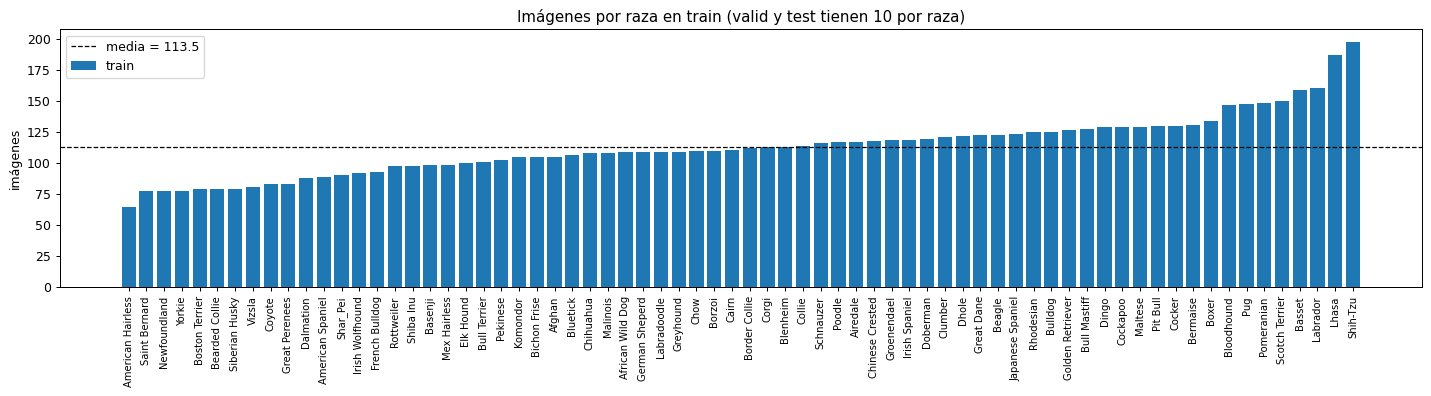

,mean,median,min,max,std,max/min
split,,,,,,
train,113.5,111.5,65.0,198.0,24.7,3.05
valid,10.0,10.0,10.0,10.0,0.0,1.00
test,10.0,10.0,10.0,10.0,0.0,1.00


In [10]:
order = counts["train"].sort_values().index
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.bar(range(len(order)), counts.loc[order, "train"], color="tab:blue", label="train")
ax.axhline(counts["train"].mean(), color="k", ls="--", lw=1, label=f"media = {counts['train'].mean():.1f}")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_ylabel("imágenes")
ax.set_title("Imágenes por raza en train (valid y test tienen 10 por raza)")
ax.legend()
plt.tight_layout()
plt.show()

stats = counts.agg(["mean", "median", "min", "max", "std"]).T.round(1)
stats["max/min"] = (counts.max() / counts.min()).round(2)
display(stats)

In [11]:
from scipy.stats import beta


def clopper_pearson(k: int, n: int, alpha: float = 0.05) -> tuple[float, float]:
    lo = beta.ppf(alpha / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - alpha / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi


# Intervalo de confianza del 95% para el recall de UNA raza con 80% de aciertos, segun cuantas
# imagenes de test tenga esa raza.
rows_ci = []
for n in (10, 15, 20, 30, 50):
    k = round(0.8 * n)
    lo, hi = clopper_pearson(k, n)
    rows_ci.append({"imagenes de test por raza": n, "aciertos": k, "IC 95% recall": f"[{lo:.2f}, {hi:.2f}]",
                    "ancho": round(hi - lo, 2), "1 error mueve el recall": f"{1 / n:.0%}"})
display(pd.DataFrame(rows_ci))

,imagenes de test por raza,aciertos,IC 95% recall,ancho,1 error mueve el recall
0,10,8,"[0.44, 0.97]",0.53,10%
1,15,12,"[0.52, 0.96]",0.44,7%
2,20,16,"[0.56, 0.94]",0.38,5%
3,30,24,"[0.61, 0.92]",0.31,3%
4,50,40,"[0.66, 0.90]",0.24,2%


**Interpretación.** En train hay entre **65** (American Hairless) y **198** (Shih-Tzu) imágenes por
raza, con media 113.5 y mediana 111.5: un **desbalance moderado de 3:1**. No es extremo, pero un
modelo que no lo tenga en cuenta tiende a favorecer a las razas más frecuentes; se compensa en el
entrenamiento con pesos por clase o *weighted sampling* (sección 10).

Valid y test traen **exactamente 10 imágenes por raza**. Con 10 imágenes, un solo error cambia 10
puntos el recall de esa raza, y si una raza acierta 8 de 10 el intervalo de confianza del 95% de
su recall va de 0.44 a 0.97: no permite decir si una raza anda bien o mal, ni comparar dos modelos
raza por raza. Con 20 imágenes el intervalo se achica a [0.56, 0.94]. **Por eso en la sección 11 se
re-particiona el dataset** para tener unas 20 imágenes por raza en valid y test.

### 6.2 Resoluciones, formatos y archivos corruptos

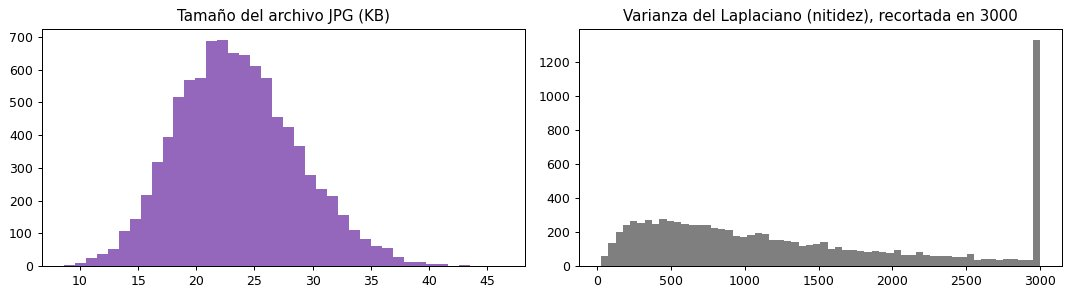

,,,,,imagenes
ext,fmt,mode,width,height,
.jpg,JPEG,RGB,224,224,9346


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(df["bytes"] / 1024, bins=40, color="tab:purple")
axes[0].set_title("Tamaño del archivo JPG (KB)")
axes[1].hist(df["lap_var"].clip(upper=3000), bins=60, color="tab:gray")
axes[1].set_title("Varianza del Laplaciano (nitidez), recortada en 3000")
plt.tight_layout()
plt.show()
display(df.groupby(["ext", "fmt", "mode", "width", "height"]).size().rename("imagenes").to_frame())

**Interpretación.** Las 9346 imágenes son **JPEG, RGB y exactamente 224×224**, y todas se pueden
leer: no hay archivos corruptos, imágenes en escala de grises ni otros formatos. Por eso el resize
es la identidad dentro del dataset (pero no para los recortes de YOLO, sección 9). El tamaño de
archivo (9–47 KB, 24 KB de media) muestra una compresión fuerte. La nitidez (varianza del
Laplaciano) varía muchísimo entre imágenes (de 25 a más de 30000): es el indicador que se usa en
la regla R3 para detectar las fotos que se ampliaron desde un original chico.

### 6.3 Muestra visual

Un ejemplo de cada una de las 70 razas (elegido al azar con la semilla fija):

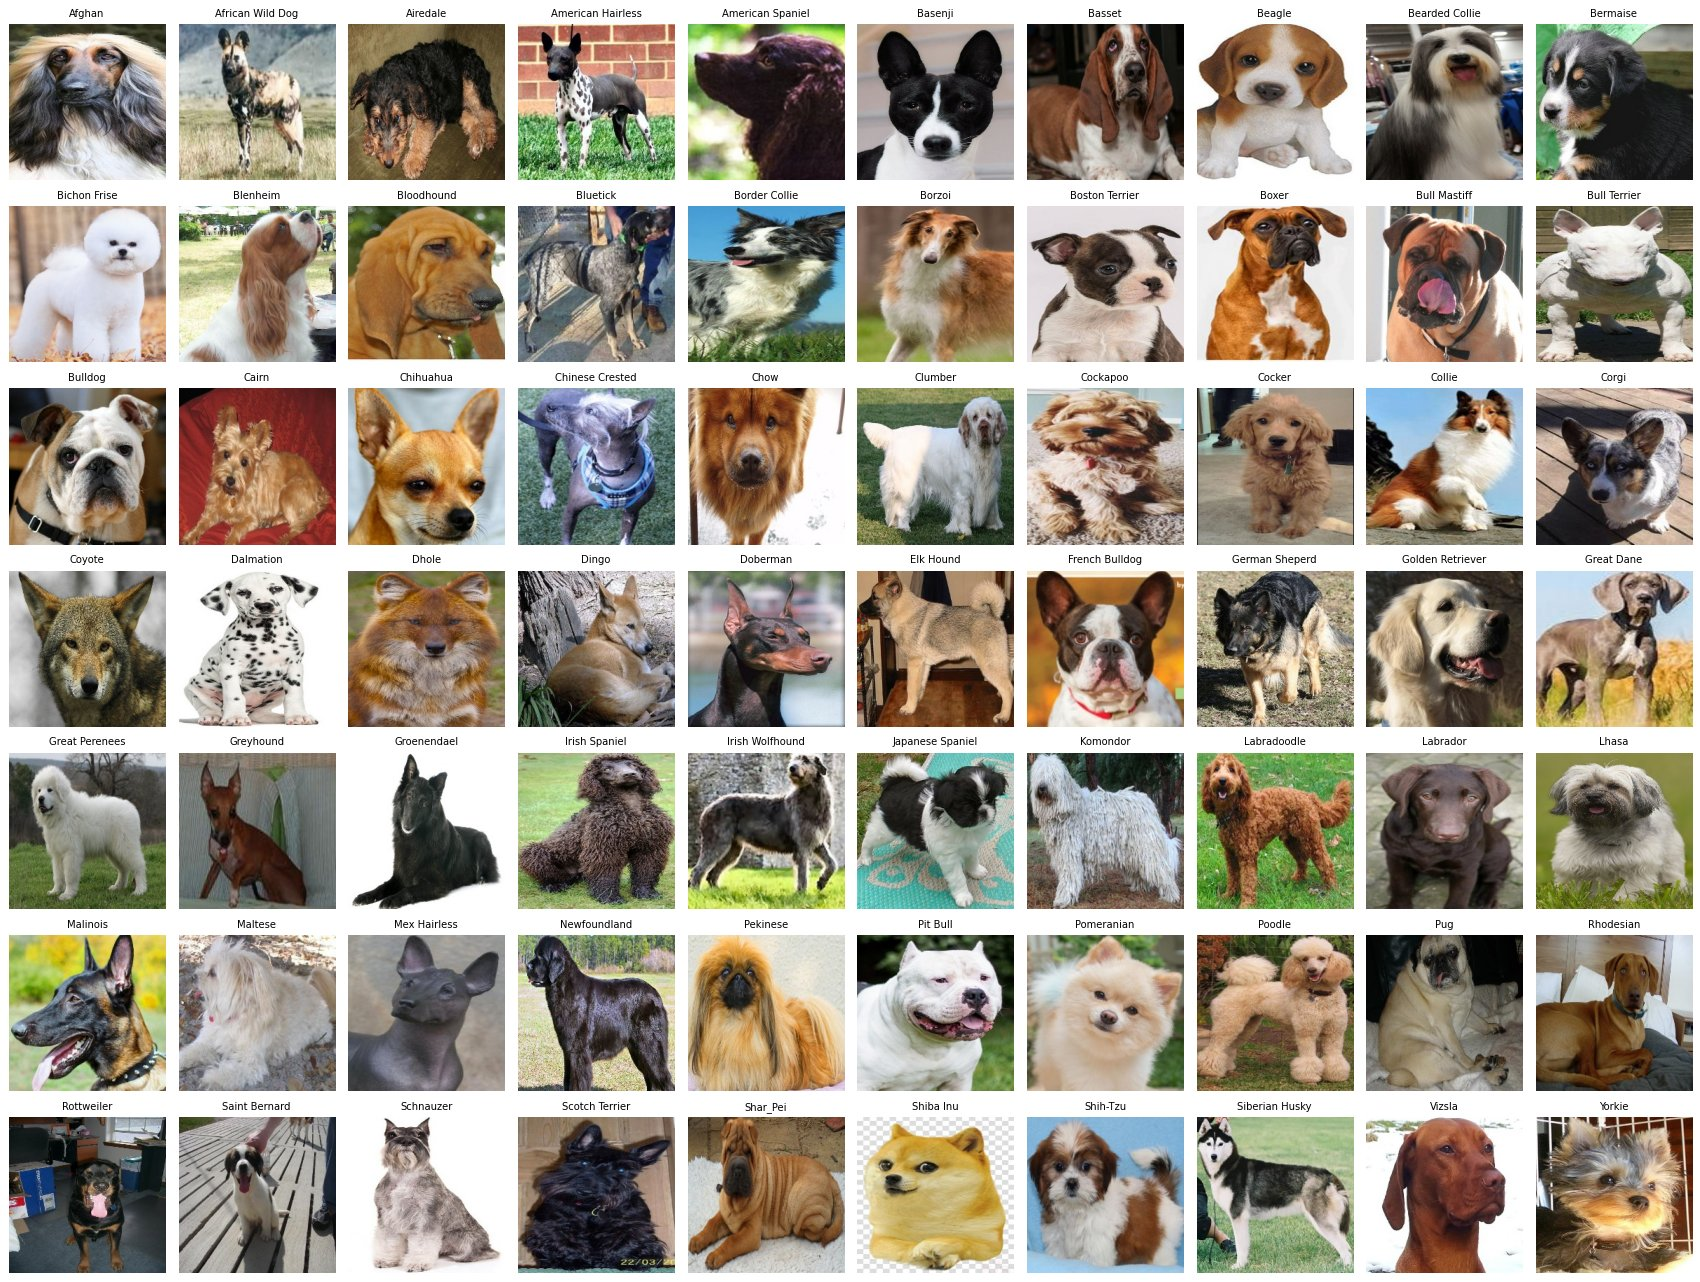

In [13]:
sample = df[df.split == "train"].groupby("breed").sample(1, random_state=SEED)
show_grid([(rgb(r.path), r.breed) for _, r in sample.iterrows()], ncols=10, size=1.9)

**Razas fáciles de confundir.** En lugar de elegir los pares a ojo, se calculan con datos: para
cada raza se promedia el embedding de ResNet18 (ImageNet) de sus imágenes de train y se buscan los
pares de razas cuyos centroides son más parecidos (similitud coseno).

,raza A,raza B,similitud
0,Boston Terrier,Bulldog,0.980
1,American Hairless,Mex Hairless,0.977
2,Lhasa,Shih-Tzu,0.974
3,Cockapoo,Labradoodle,0.967
4,German Sheperd,Malinois,0.962
5,Bulldog,French Bulldog,0.957
6,American Spaniel,Irish Spaniel,0.955
7,Boston Terrier,French Bulldog,0.953
8,American Hairless,Greyhound,0.942
9,Dingo,Shiba Inu,0.939


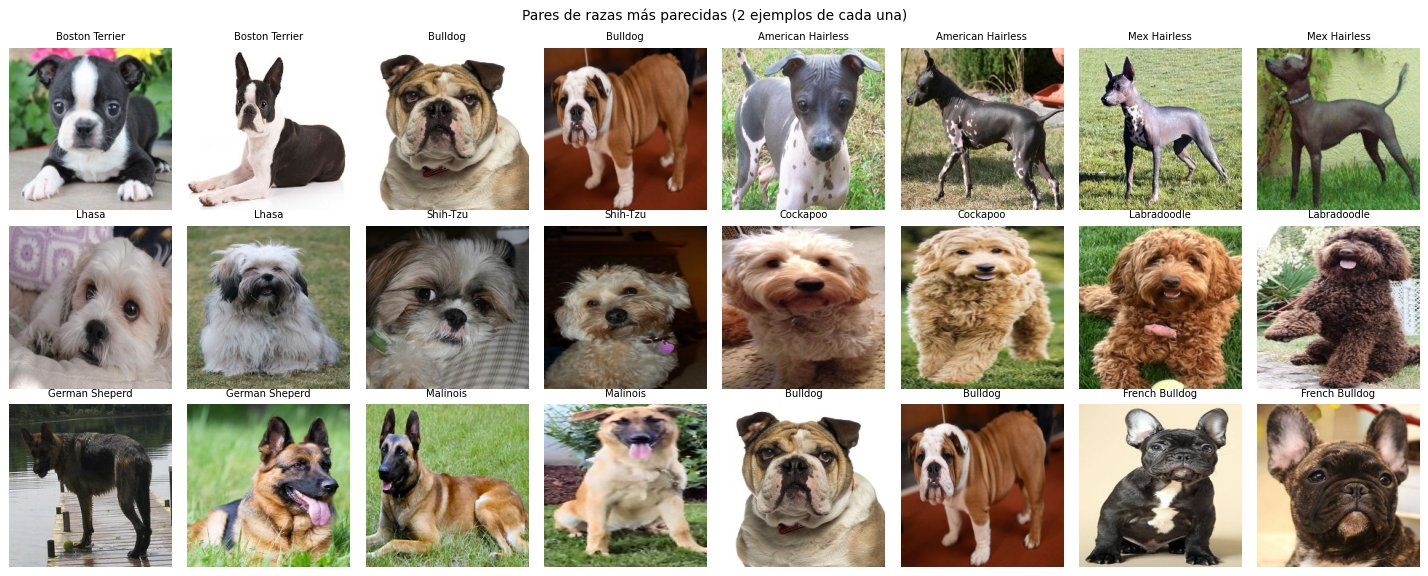

In [14]:
breeds = sorted(df["breed"].unique())
cent = np.stack([EMB[(df.breed == b).values & (df.split == "train").values].mean(0) for b in breeds])
cent /= np.linalg.norm(cent, axis=1, keepdims=True)
sim = cent @ cent.T
iu = np.triu_indices(len(breeds), 1)
pairs = (pd.DataFrame({"raza A": np.array(breeds)[iu[0]], "raza B": np.array(breeds)[iu[1]], "similitud": sim[iu]})
         .sort_values("similitud", ascending=False).head(12).reset_index(drop=True))
display(pairs.round(3))

items = []
for _, p in pairs.head(6).iterrows():
    for b in (p["raza A"], p["raza B"]):
        for _, r in df[(df.breed == b) & (df.split == "train")].sample(2, random_state=SEED).iterrows():
            items.append((rgb(r.path), b))
show_grid(items, ncols=8, size=2.0, title="Pares de razas más parecidas (2 ejemplos de cada una)")

**Interpretación.** Los pares que salen de los datos coinciden con lo que se esperaría por
conocimiento del dominio: **Boston Terrier–Bulldog** (0.980), **American Hairless–Mex Hairless**
(0.977, dos razas sin pelo casi idénticas en foto), **Lhasa–Shih-Tzu** (0.974), **Cockapoo–Labradoodle**
(0.967, las dos son cruzas con poodle), **German Sheperd–Malinois** (0.962), **Bulldog–French
Bulldog**, **American Spaniel–Irish Spaniel** (spaniels de agua de pelo rizado marrón) y
**Dingo–Shiba Inu**. Estos pares son los candidatos a dominar la matriz de confusión en
`2-train.ipynb`, y varios se incluyeron a propósito en el conjunto independiente.

### 6.4 Variaciones: iluminación, pose, fondo, oclusiones y cantidad de perros

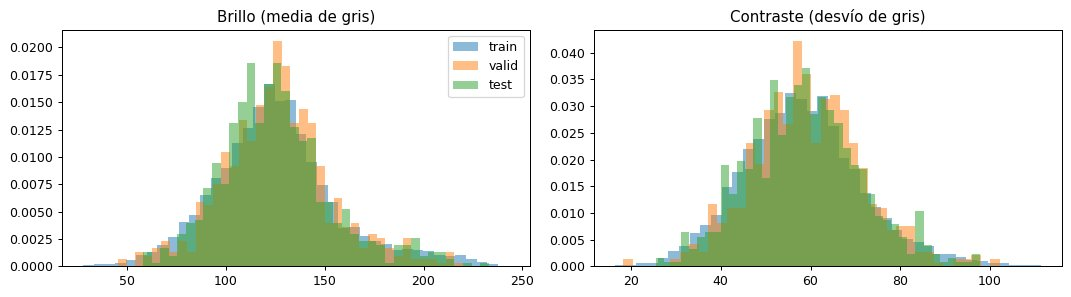

,split,test,train,valid
brightness,mean,125.6,125.6,126.1
contrast,mean,58.7,58.1,59.3
lap_var,mean,1631.3,1648.3,1606.1
brightness,50%,123.0,123.6,126.1
contrast,50%,58.3,57.6,58.8
lap_var,50%,1069.4,1072.1,1096.5
brightness,min,58.0,27.7,45.3
contrast,min,25.6,16.5,18.3
lap_var,min,57.2,24.7,42.2
brightness,max,233.1,243.0,220.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for split, c in zip(("train", "valid", "test"), ("tab:blue", "tab:orange", "tab:green")):
    sub = df[df.split == split]
    axes[0].hist(sub["brightness"], bins=40, alpha=0.5, density=True, color=c, label=split)
    axes[1].hist(sub["contrast"], bins=40, alpha=0.5, density=True, color=c, label=split)
axes[0].set_title("Brillo (media de gris)")
axes[1].set_title("Contraste (desvío de gris)")
axes[0].legend()
plt.tight_layout()
plt.show()
display(df.groupby("split")[["brightness", "contrast", "lap_var"]].describe().T.round(1).loc[(slice(None), ["mean", "50%", "min", "max"]), :])

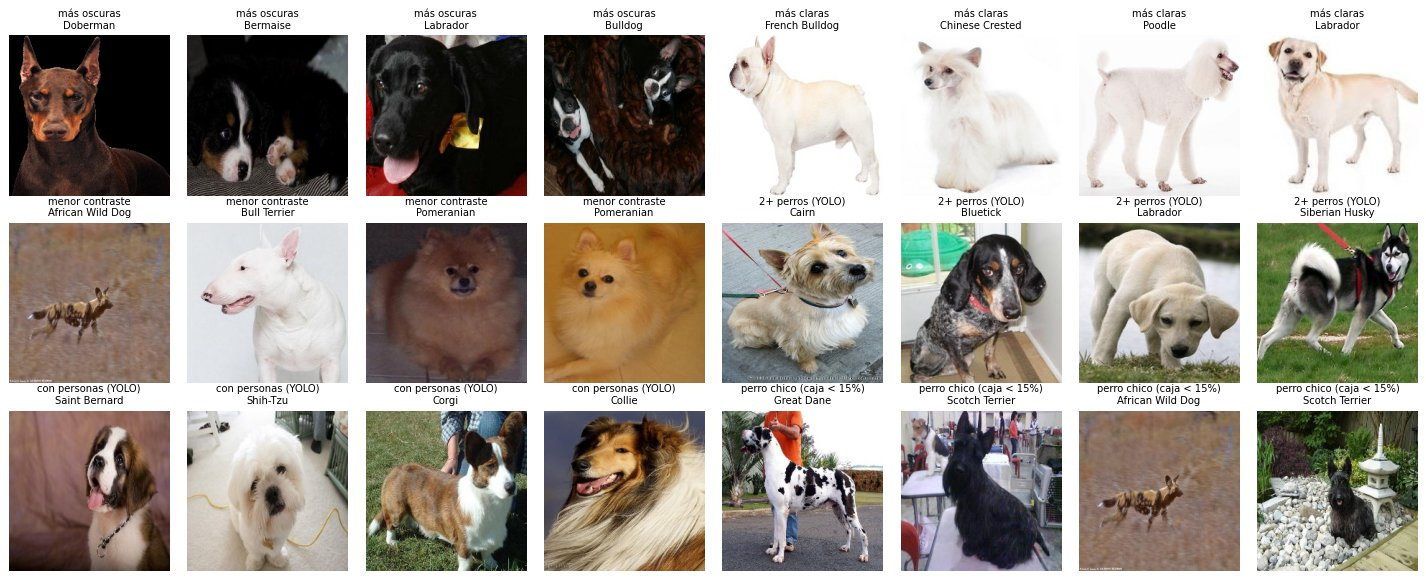

In [16]:
groups = {
    "más oscuras": df.nsmallest(4, "brightness"),
    "más claras": df.nlargest(4, "brightness"),
    "menor contraste": df.nsmallest(4, "contrast"),
    "2+ perros (YOLO)": df[df.n_dogs >= 2].sample(4, random_state=SEED),
    "con personas (YOLO)": df[df.n_persons > 0].sample(4, random_state=SEED),
    "perro chico (caja < 15%)": df[(df.n_dogs > 0) & (df.dog_area < 0.15)].sample(4, random_state=SEED),
}
items = [(rgb(r.path), f"{name}\n{r.breed}") for name, g in groups.items() for _, r in g.iterrows()]
show_grid(items, ncols=8, size=2.0)

**Interpretación.**

- **Iluminación:** las distribuciones de brillo y contraste son prácticamente iguales en train,
  valid y test (brillo medio 125.6 / 126.1 / 125.6), así que los splits originales vienen de la
  misma distribución. Los extremos no son fotos mal expuestas: las más oscuras son perros negros
  sobre fondo oscuro y las más claras son fotos de estudio con fondo blanco.
- **Fondo y pose:** conviven fotos de estudio con fondo blanco, perros de exposición parados de
  perfil, primeros planos de la cabeza y fotos caseras con el perro echado. Esa variedad se cubre
  en la augmentation con encuadres, rotaciones leves y cambios de brillo y contraste.
- **Cantidad de perros, personas y oclusiones:** según YOLO, solo ~1% de las imágenes tiene 2 o
  más perros y ~6% tiene personas, pero al mirarlas muchas son errores del detector (dos cajas
  sobre el mismo perro, o una "persona" que no existe). En los casos reales, la persona aparece
  parcialmente (piernas, manos con la correa) y no ocluye al perro. El dataset tiene casi
  exclusivamente un perro por imagen: las escenas con varios perros solo están en el conjunto
  independiente.

## 7. Control de calidad y filtrado

Reglas explícitas y reproducibles. Se aplican a **todos los splits** porque en la sección 11 se
juntan las imágenes y se vuelven a particionar: una imagen inservible o duplicada no debe quedar
en ningún split, y un duplicado entre train y test es fuga de datos.

| Regla | Criterio | Acción |
|---|---|---|
| R1 | Archivo corrupto o que no se puede leer (PIL `verify` + `cv2.imdecode`) | descartar |
| R2 | Resolución menor a 64 px en algún lado | descartar |
| R3 | Imagen borrosa: varianza del Laplaciano < `BLUR_THRESHOLD` (30) | descartar |
| R4 | Exposición extrema: brillo medio < 20 o > 245, o contraste < 12 | descartar |
| R5 | Duplicados y casi-duplicados: pHash a distancia de Hamming ≤ 4 **o** similitud coseno de embeddings ≥ 0.95 | quedarse con una por grupo (si el grupo mezcla razas, descartar todo el grupo) |
| R6 | No hay un perro visible: YOLO no detecta perro **y** el clasificador de ImageNet asigna < 10% de probabilidad a las clases de cánidos | descartar |

R6 combina dos modelos a propósito: YOLO solo tiene la clase `dog` de COCO y puede no reconocer a
un coyote o a un dhole, mientras que ImageNet sí tiene clases para lobos, coyotes, dingos y
dholes. Solo se descarta cuando ninguno de los dos ve un cánido.

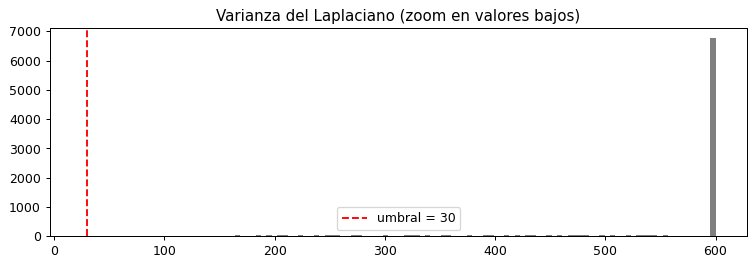

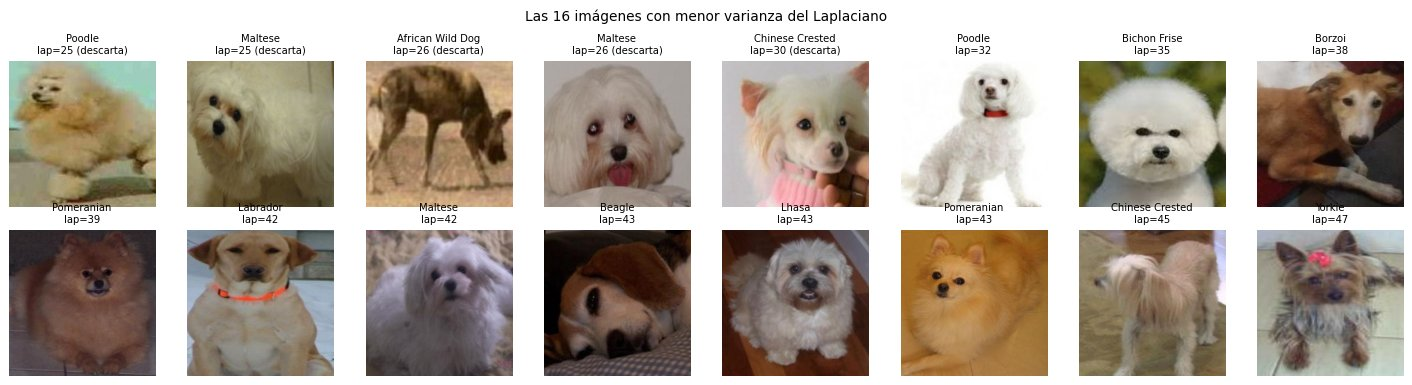

Razas entre las 100 imágenes con menor varianza del Laplaciano:


breed,Pomeranian,Pekinese,Maltese,Pit Bull,Bichon Frise,Chihuahua
imagenes,9,9,8,6,4,4


In [17]:
BLUR_THRESHOLD = 30.0  # se justifica con los ejemplos de abajo

df["R1_corrupt"] = ~df["readable"]
df["R2_small"] = (df["width"] < 64) | (df["height"] < 64)
df["R3_blur"] = df["lap_var"] < BLUR_THRESHOLD
df["R4_exposure"] = (df["brightness"] < 20) | (df["brightness"] > 245) | (df["contrast"] < 12)
df["R6_no_dog"] = (df["n_dogs"] == 0) & (df["canid_prob"] < 0.10)

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(df["lap_var"].clip(upper=600), bins=120, color="tab:gray")
ax.axvline(BLUR_THRESHOLD, color="r", ls="--", label=f"umbral = {BLUR_THRESHOLD:.0f}")
ax.set_title("Varianza del Laplaciano (zoom en valores bajos)")
ax.legend()
plt.show()

order_blur = df.sort_values("lap_var")
items = [(rgb(r.path), f"{r.breed}\nlap={r.lap_var:.0f}" + (" (descarta)" if r.R3_blur else ""))
         for _, r in order_blur.head(16).iterrows()]
show_grid(items, ncols=8, size=2.0, title="Las 16 imágenes con menor varianza del Laplaciano")
print("Razas entre las 100 imágenes con menor varianza del Laplaciano:")
display(order_blur.head(100)["breed"].value_counts().head(6).to_frame("imagenes").T)

**Interpretación.** Las imágenes con menor varianza del Laplaciano son de dos tipos: fotos
realmente borrosas (originales chicos ampliados o desenfocados) y **perros de pelaje largo y esponjoso**
(Pomeranian, Pekinese, Maltese y Bichon Frise encabezan la tabla de arriba), cuyo pelaje casi no tiene bordes aunque la foto esté nítida. La
varianza del Laplaciano mide textura, no solo foco: un umbral alto eliminaría sobre todo fotos
buenas de esas razas e introduciría un sesgo. Por eso se usa un umbral **conservador de 30**, que
solo descarta las imágenes claramente inservibles. En una primera versión se probó 40, y al mirar
los ejemplos entre 30 y 40 había fotos nítidas de perros blancos.

**R5: duplicados.** Se compara cada par de imágenes del dataset completo (9346 × 9346) con dos
criterios complementarios: el hash perceptual (pHash) encuentra copias casi exactas, aunque estén
recomprimidas o redimensionadas, y la similitud de embeddings encuentra la misma foto con
recortes o pequeñas ediciones. Los pares se agrupan en componentes conexas.

In [18]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

PHASH_MAX_DIST = 4
EMB_MIN_SIM = 0.95

hashes = np.array([np.array(imagehash.hex_to_hash(h).hash).ravel() for h in df["phash"]], dtype=np.uint8)
pairs_i, pairs_j, pairs_kind = [], [], []
for start in range(0, len(df), 1024):
    block = slice(start, start + 1024)
    ham = (hashes[block, None, :] != hashes[None, :, :]).sum(-1)
    simb = EMB[block] @ EMB.T
    for kind, mask in (("phash", ham <= PHASH_MAX_DIST), ("emb", simb >= EMB_MIN_SIM)):
        bi, bj = np.nonzero(mask)
        bi = bi + start
        keep = bi < bj
        pairs_i += list(bi[keep]); pairs_j += list(bj[keep]); pairs_kind += [kind] * keep.sum()
dup_pairs = pd.DataFrame({"i": pairs_i, "j": pairs_j, "kind": pairs_kind}).drop_duplicates(["i", "j"])
n_comp, comp = connected_components(coo_matrix((np.ones(len(dup_pairs)), (dup_pairs.i, dup_pairs.j)),
                                               shape=(len(df), len(df))), directed=False)
df["dup_group"] = comp
gsize = df.groupby("dup_group")["path"].transform("size")
df["in_dup_group"] = gsize > 1

dp = dup_pairs.assign(split_i=df.split.values[dup_pairs.i], split_j=df.split.values[dup_pairs.j],
                      breed_i=df.breed.values[dup_pairs.i], breed_j=df.breed.values[dup_pairs.j])
dp["entre_splits"] = dp.split_i != dp.split_j
dp["razas_distintas"] = dp.breed_i != dp.breed_j
print("Pares duplicados:", len(dp), "| por criterio:", dp["kind"].value_counts().to_dict())
display(dp.groupby(["entre_splits", "razas_distintas"]).size().rename("pares").to_frame())
display(pd.crosstab(dp.split_i, dp.split_j))

Pares duplicados: 906 | por criterio: {'emb': 613, 'phash': 293}


pares
entre_splits razas_distintas       
False        False              559
             True                28
True         False              319

split_j,test,train,valid
split_i,,,
test,11,0,0
train,143,562,155
valid,21,0,14


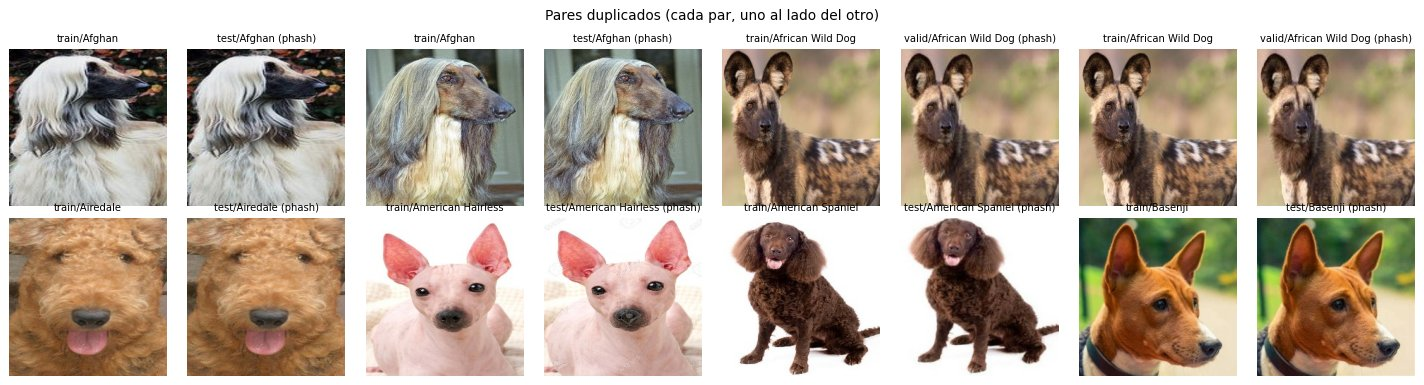

In [19]:
# Regla de resolucion: en cada grupo se conserva una sola imagen (la primera por ruta); si el grupo
# tiene mas de una raza, la etiqueta es ambigua y se descarta el grupo entero.
groups_multi_breed = df[df.in_dup_group].groupby("dup_group")["breed"].nunique()
bad_groups = set(groups_multi_breed[groups_multi_breed > 1].index)
first_in_group = ~df.sort_values("path").duplicated("dup_group").sort_index()
df["R5_duplicate"] = df.in_dup_group & (~first_in_group | df.dup_group.isin(bad_groups))

ex = dp.sort_values(["entre_splits", "razas_distintas"], ascending=False).head(8)
items = []
for _, p in ex.iterrows():
    a, b = df.iloc[p.i], df.iloc[p.j]
    items += [(rgb(a.path), f"{a.split}/{a.breed}"), (rgb(b.path), f"{b.split}/{b.breed} ({p.kind})")]
show_grid(items, ncols=8, size=2.0, title="Pares duplicados (cada par, uno al lado del otro)")

**¿Es razonable el umbral de 0.95 para los embeddings?** Los embeddings de ResNet18 salen de una
ReLU (todos sus valores son ≥ 0), así que la similitud coseno de base entre fotos distintas ya es
alta. Para validar el umbral se compara con la similitud de pares al azar y se miran pares que
**solo** detecta el criterio de embeddings (pHash a distancia > 4) justo arriba y justo abajo de 0.95.

pares al azar, misma raza:     mediana 0.793 | percentil 99: 0.903
pares al azar, raza distinta:  mediana 0.568 | percentil 99.9: 0.835


rango,"[0.93, 0.94)","[0.94, 0.95)","[0.95, 0.96)","[0.96, 0.97)","[0.97, 0.98)","[0.98, 1.001)"
pares,306.0,152.0,113.0,129.0,166.0,491.0
hamming_mediana,28.0,26.0,20.0,18.0,14.0,4.0


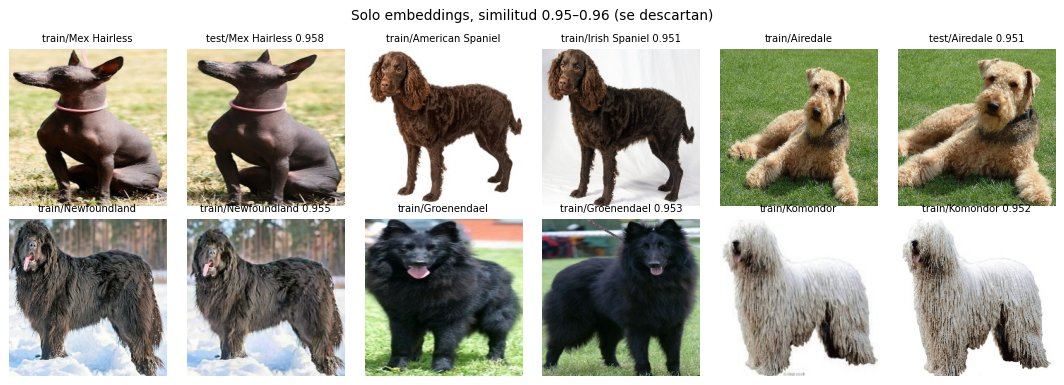

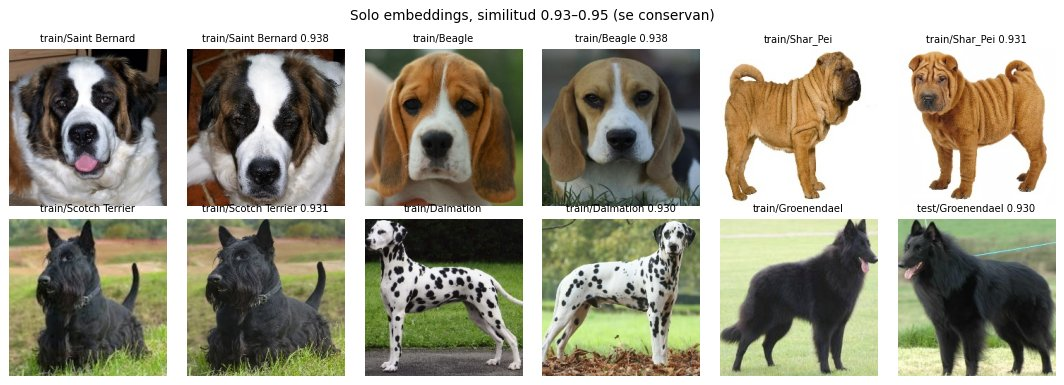

In [20]:
rng = np.random.default_rng(SEED)
ri, rj = rng.integers(0, len(df), 200_000), rng.integers(0, len(df), 200_000)
rs = (EMB[ri] * EMB[rj]).sum(1)
same_breed = (df.breed.values[ri] == df.breed.values[rj]) & (ri != rj)
print(f"pares al azar, misma raza:     mediana {np.median(rs[same_breed]):.3f} | percentil 99: {np.percentile(rs[same_breed], 99):.3f}")
print(f"pares al azar, raza distinta:  mediana {np.median(rs[~same_breed]):.3f} | percentil 99.9: {np.percentile(rs[~same_breed], 99.9):.3f}")

near_rows = []
for start in range(0, len(df), 1024):
    sl = slice(start, start + 1024)
    simb = EMB[sl] @ EMB.T
    bi, bj = np.nonzero(simb >= 0.93)
    bi = bi + start
    m = bi < bj
    for a, b in zip(bi[m], bj[m]):
        near_rows.append((a, b, float(EMB[a] @ EMB[b]), int((hashes[a] != hashes[b]).sum())))
near = pd.DataFrame(near_rows, columns=["i", "j", "sim", "hamming"])
near["rango"] = pd.cut(near.sim, [0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 1.001], right=False)
display(near.groupby("rango", observed=True).agg(pares=("sim", "size"), hamming_mediana=("hamming", "median")).T)

for lo, hi, title in [(0.95, 0.96, "Solo embeddings, similitud 0.95–0.96 (se descartan)"),
                      (0.93, 0.95, "Solo embeddings, similitud 0.93–0.95 (se conservan)")]:
    sub = near[(near.sim >= lo) & (near.sim < hi) & (near.hamming > PHASH_MAX_DIST)].sample(6, random_state=SEED)
    items = []
    for _, p in sub.iterrows():
        a, b = df.iloc[p.i], df.iloc[p.j]
        items += [(rgb(a.path), f"{a.split}/{a.breed}"), (rgb(b.path), f"{b.split}/{b.breed} {p.sim:.3f}")]
    show_grid(items, ncols=6, size=2.0, title=title)

**Interpretación.**

- **El dataset tiene fuga de datos, aunque el autor dice lo contrario.** Hay **906 pares**
  duplicados o casi duplicados; **319 están en splits distintos** (143 entre train y test, 155
  entre train y valid y 21 entre valid y test). Con los splits originales, un modelo podría
  "acertar" en test por haber visto la misma foto en train, y en la Etapa 1 la búsqueda
  devolvería la misma imagen como vecino más cercano: el NDCG@10 saldría artificialmente alto.
- **Conflictos de etiqueta:** 28 pares son la misma foto con **dos razas distintas** (por ejemplo,
  la misma foto como Rhodesian y como Vizsla). Como no se puede saber cuál es la correcta, se
  descarta el grupo entero.
- **Umbral de 0.95:** dos fotos distintas de la misma raza tienen una similitud mediana de 0.79
  (percentil 99: 0.90). Por encima de 0.96 los pares que solo detecta el criterio de embeddings
  son la misma foto recortada, espejada o recomprimida. Entre 0.95 y 0.96 aparecen además fotos
  distintas **del mismo perro en la misma sesión**: también se descartan, porque si una queda en
  train y otra en test el modelo reconoce al individuo y no a la raza. Por debajo de 0.95 son casi
  siempre fotos distintas, aunque quedan algunos casos de la misma sesión (por ejemplo, Lhasa con
  0.939): es una limitación residual que se acepta, porque bajar el umbral empezaría a eliminar
  fotos distintas de razas muy uniformes.

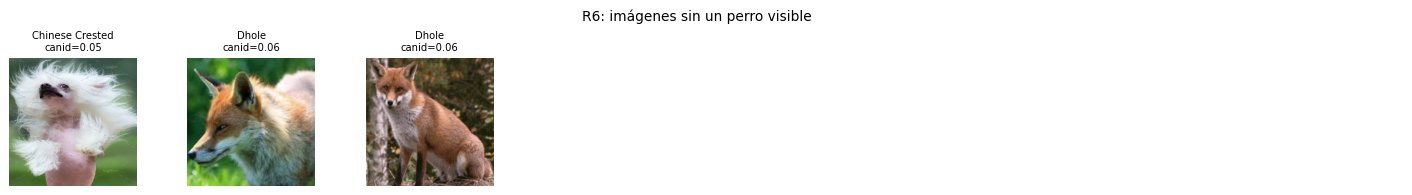

Imágenes descartadas por R4: 0


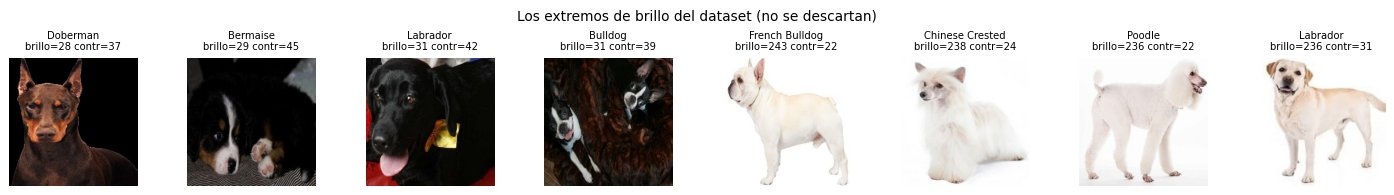

In [21]:
items = [(rgb(r.path), f"{r.breed}\ncanid={r.canid_prob:.2f}") for _, r in df[df.R6_no_dog].head(16).iterrows()]
if items:
    show_grid(items, ncols=8, size=2.0, title="R6: imágenes sin un perro visible")
print("Imágenes descartadas por R4:", int(df.R4_exposure.sum()))
ext = pd.concat([df.nsmallest(4, "brightness"), df.nlargest(4, "brightness")])
items = [(rgb(r.path), f"{r.breed}\nbrillo={r.brightness:.0f} contr={r.contrast:.0f}") for _, r in ext.iterrows()]
show_grid(items, ncols=8, size=2.0, title="Los extremos de brillo del dataset (no se descartan)")

**Interpretación.** La regla R6 marca solo 3 imágenes. **Dos están mal etiquetadas:** las fotos de
la clase Dhole son **zorros colorados**, no dholes (R6 funciona como detector de etiquetas
erróneas). La tercera es un Chinese Crested real fotografiado en una pose poco común: es un falso
positivo de la regla y se pierde una imagen, un costo bajo. No se descarta ninguna imagen por
exposición (R4): los extremos son perros negros o fondos blancos, que son fotos válidas. En una
primera versión R4 descartaba las imágenes con brillo > 230 y eliminaba justamente esas fotos de
estudio, así que se dejó solo para casos realmente extremos.

In [22]:
RULES = ["R1_corrupt", "R2_small", "R3_blur", "R4_exposure", "R5_duplicate", "R6_no_dog"]
df["discard"] = df[RULES].any(axis=1)
report = pd.DataFrame({
    "descarta (la regla sola)": df[RULES].sum(),
    "descarta (por primera vez, en orden)": [(df[r] & ~df[RULES[:k]].any(axis=1)).sum() for k, r in enumerate(RULES)],
})
report.loc["total"] = [df["discard"].sum(), df["discard"].sum()]
display(report)
display(df.groupby("split")["discard"].agg(["sum", "mean"]).rename(columns={"sum": "descartadas", "mean": "fraccion"}).round(3))

,descarta (la regla sola),"descarta (por primera vez, en orden)"
R1_corrupt,0,0
R2_small,0,0
R3_blur,5,5
R4_exposure,0,0
R5_duplicate,774,774
R6_no_dog,3,3
total,782,782


,descartadas,fraccion
split,,
test,11,0.016
train,627,0.079
valid,144,0.206


**Interpretación.** El filtrado descarta **782 imágenes (8.4%)**, casi todas por
duplicados (R5). El split más afectado es **valid (≈20%)**: buena parte de sus imágenes son copias
de imágenes de train, así que el valid original habría sobreestimado el desempeño. El filtrado se
aplica igual a todos los splits porque después se re-particiona: ninguna imagen inservible o
duplicada puede terminar en ningún split.

## 8. Conjunto independiente de evaluación

Se arma con `scripts/build_independent_set.py` a partir de **Wikimedia Commons**, donde cada
archivo tiene autor y licencia libre (CC0, CC BY, CC BY-SA o dominio público). Se descartaron
otras fuentes: Stanford Dogs sale de ImageNet (los modelos preentrenados ya vieron esas fotos),
Oxford-IIIT Pets cubre pocas razas y no trae licencia por imagen, y las imágenes de buscadores
tienen licencia desconocida.

El script busca en el árbol de la categoría de cada raza, filtra por licencia y por palabras del
título (dibujos, estatuas, personas, etc.), sortea candidatas con semilla fija y las descarga.
Después **todas las candidatas se revisaron a mano** y se descartaron las que no servían (motivo
anotado en `reason`). El resultado se guarda en `data/independent_sources.csv` (versionado) y las
imágenes en `data/dataset/independent/<raza>/` y `data/dataset/independent_scenes/<escena>/`,
fuera del control de versiones. Se comparten con los docentes como zip, con un link de solo
lectura que está en el README (`python scripts/build_independent_set.py package` arma el zip, con
el autor y la licencia de cada imagen). Con `python scripts/build_independent_set.py download`
se reconstruye desde el CSV.

Contenido:
- **24 razas** con imágenes de un solo perro (Etapas 1 y 2), incluyendo pares fáciles de confundir
  dentro del dataset: Labrador/Golden Retriever, Collie/Border Collie, Malinois/German Sheperd,
  Bulldog/French Bulldog, Maltese/Bichon Frise y Shih-Tzu/Lhasa.
- **`multi_dog`**: escenas con varios perros (Etapa 3).
- **`no_dog`**: gatos y zorros, para medir falsos positivos del detector (Etapa 3).

In [23]:
src = pd.read_csv(ROOT / "data" / "independent_sources.csv")
src["path"] = [str((INDEP if g == "breed" else SCENES) / l / Path(f).name) for g, l, f in zip(src.group, src.label, src.file)]
print("Imágenes:", len(src), "| razas:", src.loc[src.group == "breed", "label"].nunique())
display(src.groupby(["group"]).size().rename("imagenes").to_frame())
display(src[src.group == "breed"].groupby("label").size().rename("imagenes").to_frame().T)
display(src["license"].value_counts().rename("imagenes").to_frame())

Imágenes: 133 | razas: 24


,imagenes
group,
breed,100
multi_dog,13
no_dog,20


label,Beagle,Bichon Frise,Border Collie,Boxer,Bulldog,Chihuahua,Collie,Corgi,Dalmation,Dingo,...,Labrador,Lhasa,Malinois,Maltese,Poodle,Pug,Rottweiler,Shiba Inu,Shih-Tzu,Siberian Husky
imagenes,5,4,5,5,5,5,2,4,5,2,...,5,4,5,4,3,3,5,4,4,5


,imagenes
license,
CC BY-SA 4.0,48
CC BY-SA 3.0,24
CC BY-SA 2.0,15
CC BY 2.0,13
Public domain,12
CC0,7
CC BY 3.0,6
CC BY 4.0,3
CC BY-SA 2.5,3


In [24]:
ind_csv, ind_npy = CACHE / "independent_features.csv", CACHE / "independent_embeddings.npy"
if ind_csv.exists() and ind_npy.exists():
    ind_feats, IND_EMB = pd.read_csv(ind_csv, dtype={"phash": str}), np.load(ind_npy)
else:
    ind_feats, IND_EMB = analyze_images([Path(p) for p in src["path"]], batch=32)
    ind_feats.to_csv(ind_csv, index=False)
    np.save(ind_npy, IND_EMB)
ind = pd.concat([src.reset_index(drop=True), ind_feats], axis=1)

# Que no pertenezcan al dataset: mismo criterio de duplicados de la regla R5 contra las 9346 imagenes.
ind_hash = np.array([np.array(imagehash.hex_to_hash(h).hash).ravel() for h in ind["phash"]], dtype=np.uint8)
ind["min_hamming_dataset"] = (ind_hash[:, None, :] != hashes[None, :, :]).sum(-1).min(1)
ind["max_sim_dataset"] = (IND_EMB @ EMB.T).max(1)
ind["in_dataset"] = (ind.min_hamming_dataset <= PHASH_MAX_DIST) | (ind.max_sim_dataset >= EMB_MIN_SIM)
print("Imágenes del conjunto independiente que coinciden con el dataset:", int(ind["in_dataset"].sum()))
display(ind.groupby("group")[["n_dogs", "n_persons", "n_cats"]].agg(["mean", "max"]).round(2))
display(ind.groupby("group")[["max_sim_dataset"]].describe().round(3))

Imágenes del conjunto independiente que coinciden con el dataset: 0


n_dogs     n_persons     n_cats    
            mean max      mean max   mean max
group                                        
breed       0.92   2      0.34   5   0.10   1
multi_dog   1.85   4      0.08   1   0.08   1
no_dog      0.10   1      0.10   2   0.75   2

max_sim_dataset                                                 
                    count   mean    std    min    25%    50%    75%    max
group                                                                     
breed               100.0  0.836  0.043  0.711  0.810  0.843  0.869  0.902
multi_dog            13.0  0.777  0.062  0.642  0.735  0.774  0.828  0.882
no_dog               20.0  0.754  0.050  0.633  0.723  0.755  0.771  0.853

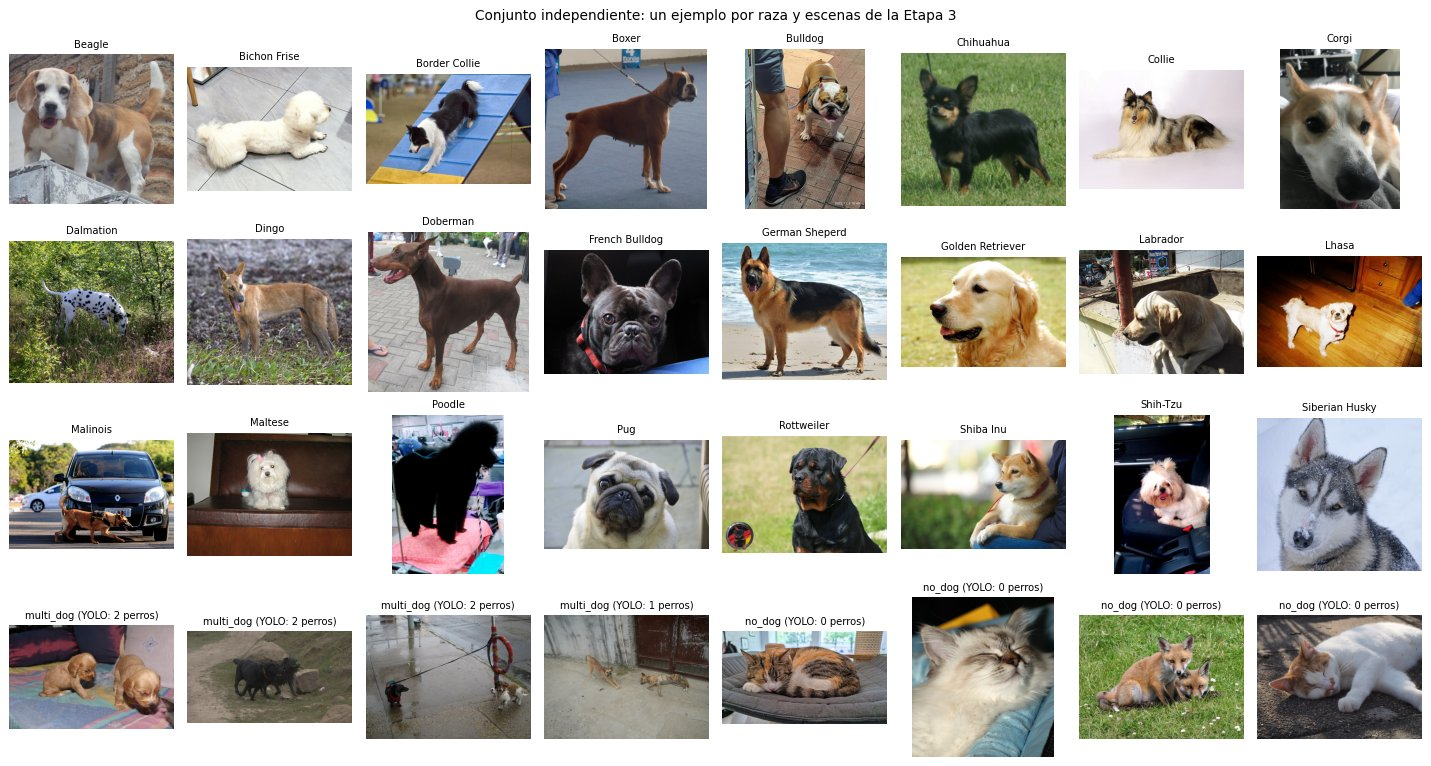

In [25]:
items = []
for label, g in ind[ind.group == "breed"].groupby("label"):
    r = g.iloc[0]
    items.append((bgr_to_rgb(read_bgr(r.path)), label))
for scene in ("multi_dog", "no_dog"):
    for _, r in ind[ind.group == scene].head(4).iterrows():
        items.append((bgr_to_rgb(read_bgr(r.path)), f"{scene} (YOLO: {r.n_dogs} perros)"))
show_grid(items, ncols=8, size=2.0, title="Conjunto independiente: un ejemplo por raza y escenas de la Etapa 3")

**Interpretación.**

- **Revisión manual:** de 271 candidatas se descartaron 128 (47%). Los motivos más comunes fueron
  una raza dudosa o distinta de la categoría (36), por ejemplo un Rough Collie en la categoría
  Border Collie o caniches cruza en Poodle, y fotos que no sirven para evaluar: perro chico o
  lejano, fotos históricas en blanco y negro, dibujos o pinturas, y personas en primer plano o
  con la cara reconocible. Para
  las escenas `multi_dog` solo se aceptaron fotos reales con dos o más perros. Los filtros
  automáticos por título dejaban pasar casi la mitad de basura: sin la revisión manual el conjunto
  mediría errores de etiqueta y no al modelo.
- **No se superpone con el dataset:** al aplicar el mismo criterio de duplicados que la regla R5,
  una candidata ("Clyde The Bulldog") resultó ser **la misma foto que `train/Bulldog/029.jpg`**
  (similitud 0.984). El autor del dataset también juntó imágenes de la web, Commons incluido, así
  que este control es necesario y no una formalidad. Esa imagen se descartó y el control da 0. El
  resto tiene una similitud máxima con el dataset de 0.84 de mediana: son fotos parecidas
  (la misma raza) pero no copias.
- **Es distinto al dataset en lo que importa:** fotos de tamaño y relación de aspecto variables,
  perros de cuerpo entero con fondo y contexto, personas y correas, en lugar de recortes
  224×224 ya centrados. Es la situación de la Etapa 3. En este conjunto YOLO detecta al menos un
  perro en el **91%** de las fotos de razas, contra el **55%** en el dataset: confirma que lo que le
  cuesta a YOLO es el encuadre ajustado del dataset, no los perros en sí.
- **Limitaciones:** son 100 imágenes de 24 razas, con 2 a 5 por raza (Collie y Dingo quedaron con
  2). Alcanza para medir el desempeño agregado y comparar modelos fuera de la distribución del
  dataset, pero no para conclusiones por raza. Las 46 razas restantes no tienen imágenes
  independientes.

## 9. Preprocesamiento

El pipeline está en `src/lib/preprocessing.py` y lo importan esta notebook, `2-train.ipynb` y los
tres servicios de la app, así no puede haber diferencias entre entrenamiento e inferencia:

```
imagen BGR uint8 (cv2 / app) -> RGB -> letterbox a IMAGE_SIZE x IMAGE_SIZE -> [0, 1] -> (x - mean) / std -> CHW float32
```

**Orden de canales.** La app entrega imágenes BGR (OpenCV); torchvision y los pesos de ImageNet
esperan RGB. Abajo se ve el efecto de olvidarse la conversión: la imagen parece normal en
estructura pero los colores (y por lo tanto el pelaje) cambian.

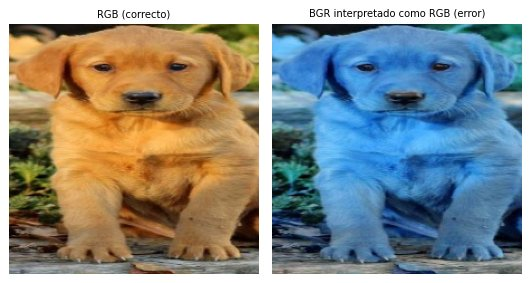

In [26]:
r = df[df.breed == "Golden Retriever"].iloc[3]
bgr = read_bgr(RAW / r.path)
show_grid([(bgr_to_rgb(bgr), "RGB (correcto)"), (bgr, "BGR interpretado como RGB (error)")], ncols=2, size=3)

**Resize.** Todas las imágenes del dataset ya son 224×224, así que en entrenamiento el resize es
la identidad. Importa en la Etapa 3: los recortes de YOLO tienen cualquier relación de aspecto.
Se comparan tres opciones sobre un recorte alargado del conjunto independiente:

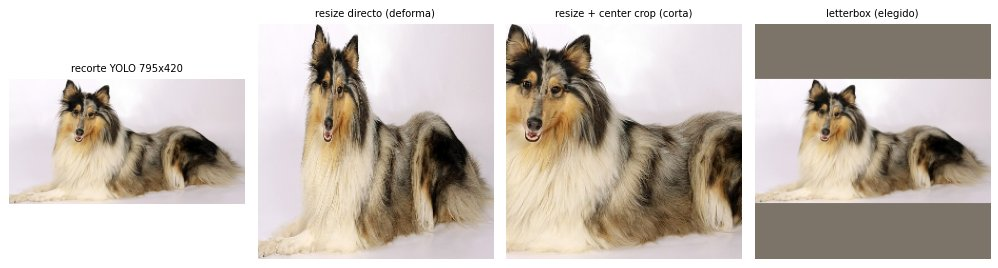

In [27]:
cand = ind[(ind.group == "breed") & (ind.n_dogs == 1)]
yolo_demo = YOLO("models/yolov8n.pt")
crop = None
for _, r in cand.iterrows():
    img = bgr_to_rgb(read_bgr(r.path))
    res = yolo_demo(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), conf=0.25, classes=[COCO_DOG], verbose=False)[0]
    if len(res.boxes):
        x1, y1, x2, y2 = res.boxes.xyxy[0].cpu().numpy().astype(int)
        if (x2 - x1) / max(1, y2 - y1) > 1.6:
            crop = img[y1:y2, x1:x2]
            break


def center_crop(img, size):
    h, w = img.shape[:2]
    s = size / min(h, w)
    img = cv2.resize(img, (round(w * s), round(h * s)))
    h, w = img.shape[:2]
    return img[(h - size) // 2:(h - size) // 2 + size, (w - size) // 2:(w - size) // 2 + size]


show_grid([(crop, f"recorte YOLO {crop.shape[1]}x{crop.shape[0]}"),
           (cv2.resize(crop, (IMAGE_SIZE, IMAGE_SIZE)), "resize directo (deforma)"),
           (center_crop(crop, IMAGE_SIZE), "resize + center crop (corta)"),
           (letterbox(crop, IMAGE_SIZE), "letterbox (elegido)")], ncols=4, size=2.8)

Se elige **letterbox**: escala el lado mayor a 224 y completa con relleno, sin deformar las
proporciones del perro (que son un rasgo de la raza: un basset deformado deja de parecer un
basset) y sin cortar la cabeza o la cola como el *center crop*. El relleno usa el color medio de
ImageNet, que después de normalizar queda en ≈0 (el mismo valor que el *padding* de las
convoluciones), así que no introduce bordes artificiales. Como las imágenes de entrenamiento son
cuadradas y no tienen relleno, la augmentation incluye recortes aleatorios (`RandomResizedCrop`)
y desplazamientos con relleno (`Affine`) para que el modelo también vea encuadres parciales.

**Normalización.** Para los modelos preentrenados (baseline y ResNet fine-tuned) es obligatorio
usar la media y el desvío de ImageNet, porque sus pesos se aprendieron con esa escala. Para la CNN
propia se calculan las estadísticas de train y se comparan:

In [28]:
acc, acc2, n = np.zeros(3), np.zeros(3), 0
train_paths = df.loc[(df.split == "train") & ~df.discard, "path"]
for p in train_paths.sample(2000, random_state=SEED):
    x = rgb(p).reshape(-1, 3) / 255.0
    acc += x.sum(0); acc2 += (x ** 2).sum(0); n += len(x)
mean = acc / n
std = np.sqrt(acc2 / n - mean ** 2)
display(pd.DataFrame({"media train": mean, "media ImageNet": IMAGENET_MEAN,
                      "desvío train": std, "desvío ImageNet": IMAGENET_STD}, index=["R", "G", "B"]).round(3))

,media train,media ImageNet,desvío train,desvío ImageNet
R,0.523,0.485,0.272,0.229
G,0.487,0.456,0.267,0.224
B,0.420,0.406,0.274,0.225


**Interpretación y decisión.** Las estadísticas de train son algo distintas de las de ImageNet
(medias ~0.03 más altas y desvíos ~20% mayores, por la cantidad de fondos blancos). Aun así se usa
**la normalización de ImageNet también para la CNN propia**:

- Un único pipeline para los tres modelos (baseline, ResNet fine-tuned y CNN propia) elimina el
  riesgo de normalizar distinto entre la notebook y la app, que es la causa número uno de que "el
  modelo ande en la notebook pero no en la app".
- La diferencia es chica: con la normalización de ImageNet, los datos de train quedan con media
  ≈0.1 y desvío ≈1.2 en vez de 0 y 1, y la BatchNorm de la primera capa de la CNN propia absorbe
  ese corrimiento de escala.

In [29]:
x = preprocess_rgb(crop, IMAGE_SIZE)
print("salida:", x.shape, x.dtype, "| min/max:", x.min().round(2), x.max().round(2),
      "| relleno ≈", x[:, 0, 0].round(3))

salida: (3, 224, 224) float32 | min/max: -2.12 2.64 | relleno ≈ [      0.006      -0.005       0.008]


## 10. Data augmentation

Se usa `albumentations` (`build_train_augmentation` en `src/lib/preprocessing.py`), **solo sobre
train** y antes del preprocesamiento. Cada transformación simula una variación que ocurre en
fotos reales o en los recortes de YOLO:

| Transformación | Rango | Por qué |
|---|---|---|
| `RandomResizedCrop` | escala 0.6–1.0, aspecto 0.75–1.33, p=0.5 | encuadres más ajustados o corridos, como los recortes de YOLO (sección 5.1) |
| `HorizontalFlip` | p=0.5 | un perro mirando a la izquierda o a la derecha es la misma raza |
| `Affine` | rotación ±15°, escala 0.9–1.1, traslación ±5%, p=0.5 | cámara inclinada o perro no centrado; ±15° es la inclinación típica de una foto a mano |
| `RandomBrightnessContrast` | ±20% brillo y contraste, p=0.5 | interior/exterior, sombra/sol (sección 6.4) |
| `GaussianBlur` / `MotionBlur` | kernel 3–5, p=0.2 | foco imperfecto o perro en movimiento, y recortes chicos ampliados |
| `GaussNoise` | desvío 2–6% del rango, p=0.2 | ruido de sensor con poca luz |

No se usan flips verticales ni rotaciones de 90° (un perro boca abajo no ocurre en fotos reales) ni
cambios de tono (*hue*) o saturación fuertes: el color del pelaje distingue razas (por ejemplo,
Golden Retriever vs. Labrador negro), y cambiarlo equivaldría a cambiar la etiqueta.

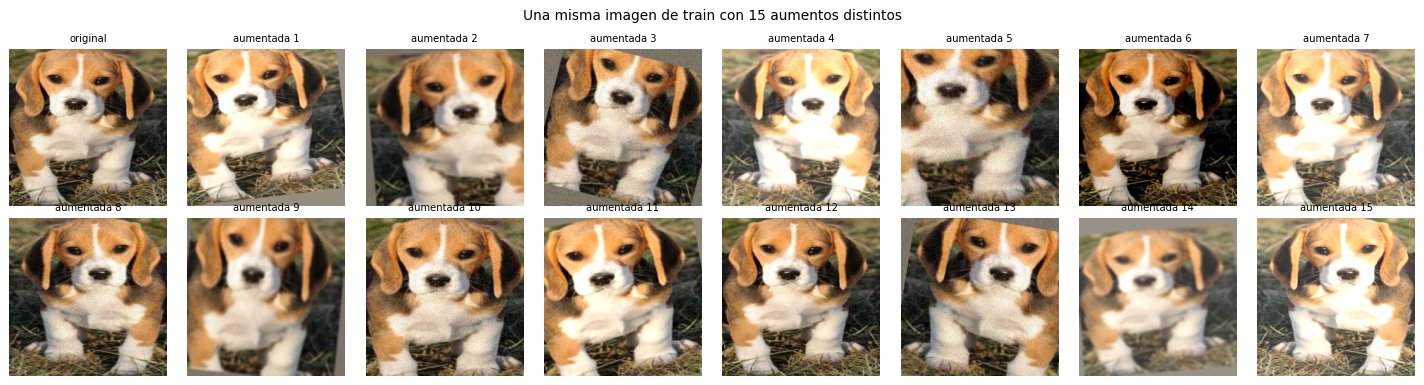

In [30]:
aug = build_train_augmentation(IMAGE_SIZE)
base = rgb(df[(df.breed == "Beagle") & (df.split == "train")].iloc[5].path)
random.seed(SEED); np.random.seed(SEED)
items = [(base, "original")] + [(aug(image=base)["image"], f"aumentada {i}") for i in range(1, 16)]
show_grid(items, ncols=8, size=2.0, title="Una misma imagen de train con 15 aumentos distintos")

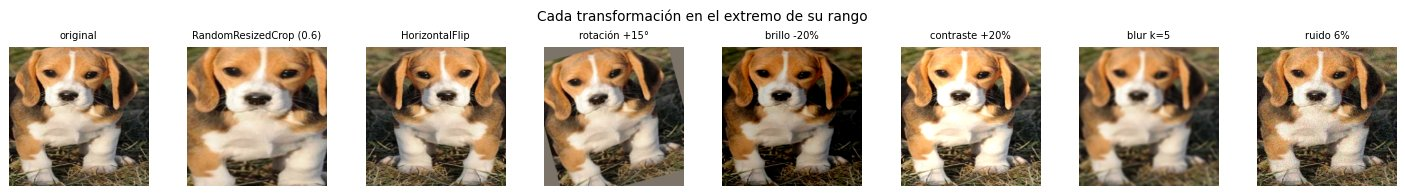

In [31]:
import albumentations as A

single = {
    "RandomResizedCrop (0.6)": A.RandomResizedCrop(size=(IMAGE_SIZE, IMAGE_SIZE), scale=(0.6, 0.6), p=1),
    "HorizontalFlip": A.HorizontalFlip(p=1),
    "rotación +15°": A.Affine(rotate=(15, 15), border_mode=cv2.BORDER_CONSTANT, fill=PAD_RGB, p=1),
    "brillo -20%": A.RandomBrightnessContrast(brightness_limit=(-0.2, -0.2), contrast_limit=0, p=1),
    "contraste +20%": A.RandomBrightnessContrast(brightness_limit=0, contrast_limit=(0.2, 0.2), p=1),
    "blur k=5": A.GaussianBlur(blur_limit=(5, 5), p=1),
    "ruido 6%": A.GaussNoise(std_range=(0.06, 0.06), p=1),
}
items = [(base, "original")] + [(t(image=base)["image"], name) for name, t in single.items()]
show_grid(items, ncols=8, size=2.0, title="Cada transformación en el extremo de su rango")

**Desbalance.** La relación entre la raza con más y con menos imágenes en train es de alrededor de
3:1 (sección 6.1), un desbalance moderado. La augmentation **no** se usa para balancear (se aplica
igual a todas las clases). Para compensar el desbalance hay dos alternativas, que se comparan en
`2-train.ipynb`: pesos por clase en la *cross-entropy* (inversamente proporcionales a la
frecuencia) o un `WeightedRandomSampler`. Los pesos se calculan en la sección 11 sobre el train
final y se guardan con los splits.

## 11. Splits

**Decisión: re-particionar.** Los splits originales tienen 10 imágenes por raza en valid y en test
(sección 6.1): con 10 imágenes, un solo error mueve 10 puntos el recall de esa raza y el intervalo
de confianza del 95% de una raza con 80% de aciertos va de 0.44 a 0.97, demasiado ancho para
comparar razas o modelos. Se juntan las imágenes que pasaron el filtrado y se dividen
**70 / 15 / 15 estratificado por raza** (semilla 42), lo que deja unas 20 imágenes por raza en
valid y en test (≈1400 imágenes cada uno) y mantiene la proporción de cada raza en los tres splits.
Como el filtrado R5 deja una sola imagen por grupo de duplicados, no puede caer la misma foto en
dos splits; igual se verifica abajo.

En la Etapa 1, `train` es la galería que se indexa y `test` + el conjunto independiente son las
consultas. Para que `scripts/build_index.py`, `train_classifier` y la app usen exactamente estos
splits sin tocar su código, los splits se **materializan** como carpetas en `data/dataset/clean/`
con la misma estructura que el dataset original (`<split>/<raza>/<imagen>`) y en el `.env` se
apunta `DATASET_PATH` ahí.

In [32]:
from sklearn.model_selection import train_test_split

kept = df[~df.discard].reset_index(drop=True)
train_idx, rest_idx = train_test_split(kept.index, test_size=0.30, stratify=kept.breed, random_state=SEED)
valid_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=kept.breed[rest_idx], random_state=SEED)
kept.loc[train_idx, "new_split"] = "train"
kept.loc[valid_idx, "new_split"] = "valid"
kept.loc[test_idx, "new_split"] = "test"

# Nombre de archivo unico: el original se repite entre splits (001.jpg en train y en test).
kept["file"] = [f"{s}_{Path(p).name}" for s, p in zip(kept.split, kept.path)]
kept["clean_path"] = [f"{s}/{b}/{f}" for s, b, f in zip(kept.new_split, kept.breed, kept.file)]
display(pd.crosstab(kept.breed, kept.new_split)[["train", "valid", "test"]].describe().round(1))

new_split,train,valid,test
count,70.0,70.0,70.0
mean,85.6,18.4,18.4
std,16.3,3.6,3.6
min,53.0,11.0,11.0
25%,76.2,16.0,16.0
50%,84.5,18.0,18.0
75%,92.8,20.0,19.8
max,143.0,31.0,31.0


In [33]:
# Verificacion de fuga: ningun par duplicado (pHash u embeddings) en splits distintos.
pos = {orig: k for k, orig in enumerate(kept.path)}
idx_kept = df.index[~df.discard].values
kept_hash, kept_emb = hashes[idx_kept], EMB[idx_kept]
leaks = 0
for start in range(0, len(kept), 1024):
    sl = slice(start, start + 1024)
    ham = (kept_hash[sl, None, :] != kept_hash[None, :, :]).sum(-1)
    simb = kept_emb[sl] @ kept_emb.T
    bi, bj = np.nonzero((ham <= PHASH_MAX_DIST) | (simb >= EMB_MIN_SIM))
    bi = bi + start
    m = bi < bj
    leaks += int((kept.new_split.values[bi[m]] != kept.new_split.values[bj[m]]).sum())
print("Pares casi-duplicados entre splits distintos:", leaks)
assert leaks == 0
assert not set(kept.loc[kept.new_split == "train", "path"]) & set(kept.loc[kept.new_split == "test", "path"])

Pares casi-duplicados entre splits distintos: 0


In [34]:
import shutil

# Materializa data/dataset/clean/<split>/<raza>/<imagen> (se regenera completo en cada corrida).
if CLEAN.exists():
    shutil.rmtree(CLEAN)
for src_rel, dst_rel in zip(kept.path, kept.clean_path):
    dst = CLEAN / dst_rel
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(RAW / src_rel, dst)

classes = sorted(kept.breed.unique())
freq = kept[kept.new_split == "train"].breed.value_counts().reindex(classes)
class_weights = (len(kept[kept.new_split == "train"]) / (len(classes) * freq)).round(4)

splits_out = kept[["clean_path", "breed", "new_split", "path"]].rename(
    columns={"clean_path": "path", "new_split": "split", "path": "original_path"})
splits_out.to_csv(ROOT / "data" / "splits.csv", index=False)
(ROOT / "data" / "classes.json").write_text(json.dumps(
    {"classes": classes, "class_weights": class_weights.tolist(), "seed": SEED,
     "dataset_path": "data/dataset/clean"}, ensure_ascii=False, indent=2), encoding="utf-8")

n_files = sum(1 for _ in CLEAN.rglob("*.jpg"))
print("Imágenes en data/dataset/clean:", n_files, "| clases:", len(classes))
print(splits_out.head(3).to_string(index=False))

Imágenes en data/dataset/clean: 8564 | clases: 70
                      path  breed split        original_path
train/Afghan/train_001.jpg Afghan train train/Afghan/001.jpg
 test/Afghan/train_002.jpg Afghan  test train/Afghan/002.jpg
valid/Afghan/train_003.jpg Afghan valid train/Afghan/003.jpg


Archivos generados:
- `data/splits.csv`: una fila por imagen con `path` (relativo a `data/dataset/clean`), `breed`,
  `split` y `original_path` (relativo a `data/dataset`, para rastrear de dónde salió).
- `data/classes.json`: la lista ordenada de las 70 razas (**define el índice de cada clase** para
  los dos modelos y la app) y los pesos por clase calculados sobre train.
- `data/dataset/clean/`: las imágenes copiadas por split y raza (fuera del control de versiones;
  se regeneran corriendo esta notebook).

## 12. Resumen final

In [35]:
final = pd.crosstab(kept.breed, kept.new_split)[["train", "valid", "test"]]
ind_breed_counts = src[src.group == "breed"].groupby("label").size()
resumen = pd.DataFrame({
    "razas": [final.shape[0]] * 3 + [ind_breed_counts.size, 0, 0],
    "imagenes": [final["train"].sum(), final["valid"].sum(), final["test"].sum(), ind_breed_counts.sum(),
                 (src.group == "multi_dog").sum(), (src.group == "no_dog").sum()],
    "imagenes por raza (min-max)": [f"{final[c].min()}-{final[c].max()}" for c in ("train", "valid", "test")]
                                   + [f"{ind_breed_counts.min()}-{ind_breed_counts.max()}", "-", "-"],
}, index=["train", "valid", "test", "independiente (1 perro)", "independiente: varios perros", "independiente: sin perros"])
resumen.loc["dataset original"] = [counts.shape[0], len(inv), f"{counts.min().min()}-{counts.max().max()}"]
resumen.loc["descartadas por el filtrado"] = ["-", int(df.discard.sum()), "-"]
display(resumen)

,razas,imagenes,imagenes por raza (min-max)
train,70,5994,53-143
valid,70,1285,11-31
test,70,1285,11-31
independiente (1 perro),24,100,2-5
independiente: varios perros,0,13,-
independiente: sin perros,0,20,-
dataset original,70,9346,10-198
descartadas por el filtrado,-,782,-


## 13. Licencias y uso de imágenes

- **Dataset principal:** 70 Dog Breeds Image Dataset (Kaggle, autor Gerry / `gpiosenka`),
  licencia **CC0: Public Domain**. Permite el uso académico, la modificación (filtrado,
  re-particionado) y la redistribución. Las imágenes no se suben al repositorio: se descargan con
  `scripts/download_dataset.py`.
- **Conjunto independiente:** imágenes de Wikimedia Commons con licencia CC0, CC BY, CC BY-SA o
  dominio público. La fuente (página de Commons), el autor y la licencia de **cada imagen** están
  en `data/independent_sources.csv`. Las licencias CC BY y CC BY-SA exigen atribución, que queda
  cubierta por ese CSV; las imágenes no se redistribuyen en el repositorio (se comparten con los
  docentes por un link de solo lectura y se pueden reconstruir con
  `python scripts/build_independent_set.py download`).
- **Personas identificables:** se evitaron. El script excluye títulos que mencionan personas y en
  la revisión manual se descartaron las candidatas donde aparecía una persona reconocible (por
  ejemplo, un disfraz de Cruella de Vil que aparecía dentro de la categoría "Dalmatian"). En el
  dataset de Kaggle hay imágenes con personas (sección 6.4); se mantienen porque la licencia del
  dataset lo permite y no se publican fuera de él.